<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/04_gravitational_lensing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Black Hole Simulator — Gravitational Lensing

## Objectives
- Create a synthetic background starfield
- Model light bending around a Schwarzschild black hole
- Build a simple lensing visualization
- Understand how ray tracing can produce a black hole shadow


In [2]:
import numpy as np
import matplotlib.pyplot as plt

print("Gravitational lensing notebook initialized.")

Gravitational lensing notebook initialized.


Step 3 — Define the lensing model
For this notebook, we'll start with the point-mass thin-lens approximation. This is a standard simplified gravitational-lensing model. It is easier to understand and visualize before we build a full relativistic renderer.

In [3]:
# Normalized lensing units
theta_E = 1.2

# Number of background stars
number_of_stars = 250

print("Einstein radius:", theta_E)
print("Number of background stars:", number_of_stars)

Einstein radius: 1.2
Number of background stars: 250


Generate the background stars
Add another code cell:

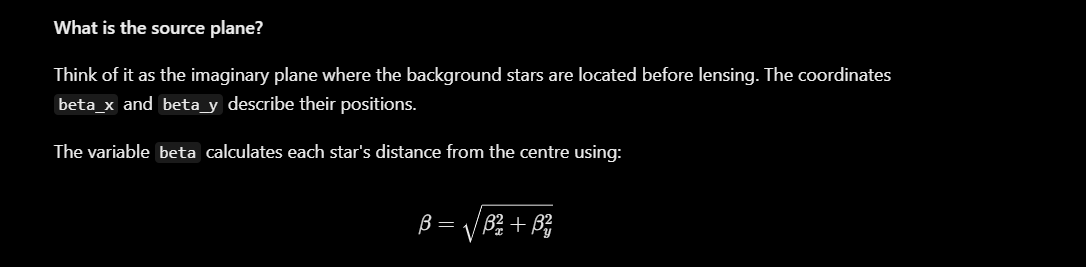

In [4]:
np.random.seed(42)

# Background star coordinates in the source plane
beta_x = np.random.uniform(-4, 4, number_of_stars)
beta_y = np.random.uniform(-4, 4, number_of_stars)

# Distance of each star from the optical axis
beta = np.sqrt(beta_x**2 + beta_y**2)

print("Generated stars:", len(beta_x))
print("Minimum source distance:", beta.min())
print("Maximum source distance:", beta.max())

Generated stars: 250
Minimum source distance: 0.3629652367805667
Maximum source distance: 5.431570204857783


Visualize the original starfield

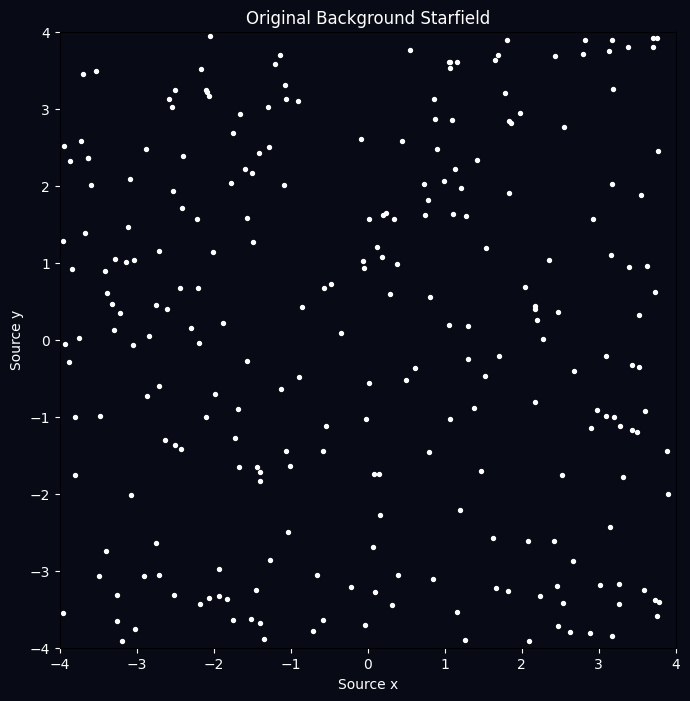

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    beta_x,
    beta_y,
    s=8,
    color="white"
)

ax.set_facecolor("#080b16")
fig.patch.set_facecolor("#080b16")

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect("equal")

ax.set_title("Original Background Starfield", color="white")
ax.set_xlabel("Source x", color="white")
ax.set_ylabel("Source y", color="white")
ax.tick_params(colors="white")

plt.show()

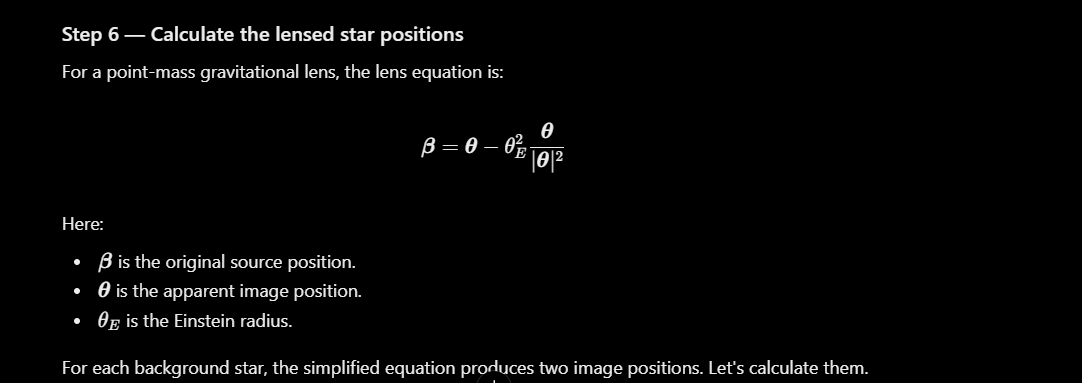

In [6]:
# Avoid division by zero for a star exactly at the centre
safe_beta = np.maximum(beta, 1e-10)

# Solve the point-mass lens equation
root = np.sqrt(beta**2 + 4 * theta_E**2)

theta_plus = (beta + root) / 2
theta_minus = (beta - root) / 2

# Convert radial image positions to x and y coordinates
theta_plus_x = theta_plus * beta_x / safe_beta
theta_plus_y = theta_plus * beta_y / safe_beta

theta_minus_x = theta_minus * beta_x / safe_beta
theta_minus_y = theta_minus * beta_y / safe_beta

print("Calculated two image positions per source star.")

Calculated two image positions per source star.


#Plot the gravitational lensing effect

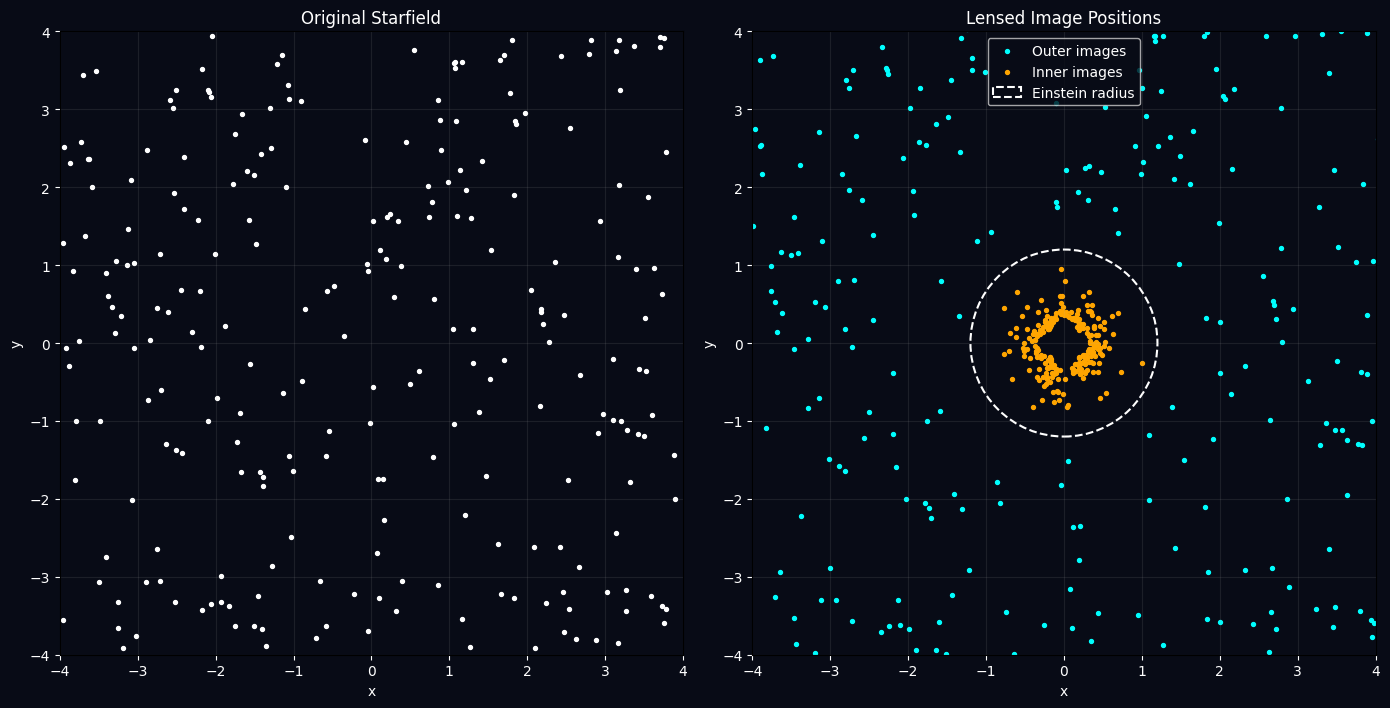

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Original background stars
axes[0].scatter(
    beta_x,
    beta_y,
    s=8,
    color="white"
)

axes[0].set_title("Original Starfield", color="white")

# Lensed image positions
axes[1].scatter(
    theta_plus_x,
    theta_plus_y,
    s=8,
    color="cyan",
    label="Outer images"
)

axes[1].scatter(
    theta_minus_x,
    theta_minus_y,
    s=8,
    color="orange",
    label="Inner images"
)

# Einstein ring reference
axes[1].add_patch(
    plt.Circle(
        (0, 0),
        theta_E,
        fill=False,
        linestyle="--",
        linewidth=1.5,
        color="white",
        label="Einstein radius"
    )
)

axes[1].set_title("Lensed Image Positions", color="white")
axes[1].legend(facecolor="#080b16", labelcolor="white")

for ax in axes:
    ax.set_facecolor("#080b16")
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.set_xlabel("x", color="white")
    ax.set_ylabel("y", color="white")
    ax.tick_params(colors="white")
    ax.grid(alpha=0.12)

fig.patch.set_facecolor("#080b16")
plt.tight_layout()
plt.show()